# JupyterLab 上手：用比赛场景走一遍

Jupyter 不是"另一个写代码的地方"，它比 `.py` 脚本多三件事：

| 能力 | 脚本 (`python test.py`) | 笔记本 (`demo.ipynb`) |
|---|---|---|
| 改一个参数看结果 | 从头重跑整个文件 | 只重跑 1 个单元（秒级） |
| 看中间量 | `print()` 完就冲掉了 | 每个单元的输出永久留在文档里 |
| 交论文/给队友看 | 只有代码 | 代码 + 公式 + 图 + 结论一起 |
| 交付格式 | .py | .ipynb（也可导出 PDF/HTML） |

下面每个单元都是**可独立执行**的：光标放进去按 `Shift+Enter`。

> 第一次打开：菜单 `Kernel → Restart Kernel and Run All Cells` 一次跑完。

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

print("Python", sys.version.split()[0])
print("numpy", np.__version__)

# 中文显示：Jupyter 里同样必须设置，否则标题里的中文会变方框
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
print("中文图设置完成")

Python 3.11.17
numpy 2.4.6
中文图设置完成


## 1. 分步执行：脚本要跑 10 分钟，笔记本改一行只要 1 秒

下面定义阻尼振动模型（一个常微分方程）。**定义一次，后面所有单元都能直接用** —— 这是笔记本最省时间的地方。

In [2]:
from scipy.integrate import solve_ivp

def damping(t, y, zeta, w0=1.0):
    """阻尼振动右端：x'' + 2*zeta*w0*x' + w0^2*x = 0"""
    x, v = y
    return [v, -2 * zeta * w0 * v - w0 ** 2 * x]

def solve(zeta, T=12.0):
    """给定阻尼比，返回数值解（t_eval 让时间网格均匀，方便直接画图）"""
    return solve_ivp(damping, (0, T), [1.0, 0.0], args=(zeta,),
                     t_eval=np.linspace(0, T, 600), rtol=1e-8)

print("模型定义完成 —— 下面每个单元都可以直接调用 solve(zeta)")

模型定义完成 —— 下面每个单元都可以直接调用 solve(zeta)


In [3]:
# 改这一个数字，按 Shift+Enter，立刻看到新结果
zeta = 0.05

sol = solve(zeta)
print(f"阻尼比 zeta = {zeta} 时：")
print(f"  12 秒后剩余振幅 = {abs(sol.y[0][-1]):.4f} m")
print(f"  峰值位移      = {sol.y[0].max():.4f} m")

# 对比：如果这是 .py 脚本，改 zeta 就得从头重跑整份文件

阻尼比 zeta = 0.05 时：
  12 秒后剩余振幅 = 0.4436 m
  峰值位移      = 1.0000 m


## 2. 富输出：公式直接渲染成排版好的数学式

不是贴图片，是 Notebook 用 MathJax 现场渲染。**符号推导的可见性极强** —— 赛题要求"给出解析解"时，这一步能直接截图进论文：

$$\zeta < 1 \;\Rightarrow\; x(t) = e^{-\zeta \omega_0 t}\cos\left(\omega_0\sqrt{1-\zeta^2}\,t\right)$$

In [4]:
import sympy as sp

t, zeta_s, w0 = sp.symbols("t zeta omega_0", positive=True)

# 欠阻尼解析解
x = sp.exp(-zeta_s * w0 * t) * sp.cos(w0 * sp.sqrt(1 - zeta_s ** 2) * t)

# 单元末尾写变量名 -> Jupyter 自动渲染成排版后的公式（不是字符串）
sp.Eq(sp.Symbol("x(t)"), x)

Eq(x(t), exp(-omega_0*t*zeta)*cos(omega_0*t*sqrt(1 - zeta**2)))

In [5]:
# 求导：验证它满足原方程（把结果代回，看是否为 0）
residual = sp.diff(x, t, 2) + 2 * zeta_s * w0 * sp.diff(x, t) + w0 ** 2 * x
sp.simplify(residual)

0

## 3. 图直接长在文档里

`plt.show()` 的输出会嵌在单元下方，随文档一起保存。改参数重跑，图就地更新 —— 不用去文件夹里翻 png。

（下面这 4 条曲线画在同一张图里，因为它们是同一个指标随参数的变化，分开看没有意义。）

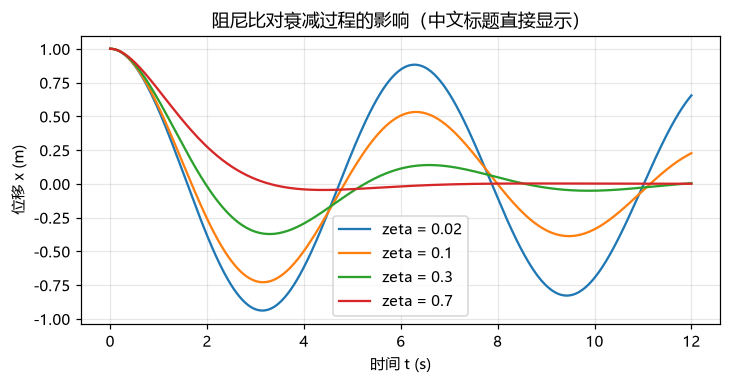

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.4), dpi=110)

for z in (0.02, 0.1, 0.3, 0.7):
    s = solve(z)
    ax.plot(s.t, s.y[0], label=f"zeta = {z}")

ax.set_xlabel("时间 t (s)")
ax.set_ylabel("位移 x (m)")
ax.set_title("阻尼比对衰减过程的影响（中文标题直接显示）")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# 论文用图建议在这一行加：fig.savefig("figs/damping.png", dpi=300, bbox_inches="tight")

## 4. 交互控件：拖滑块探索参数空间

这是 Jupyter 独有的东西 —— 在**同一个单元里拖滑块**，图实时重画。适合赛题中"找临界值""看趋势是否单调"这类探索，比反复改数字快得多。

> 依赖 `ipywidgets`（本环境已装）。若滑块不显示，执行 `conda activate upc` 后重开 JupyterLab。

In [7]:
from ipywidgets import interact, FloatSlider

@interact(zeta=FloatSlider(value=0.1, min=0.0, max=1.0, step=0.05, description="阻尼比"))
def explore(zeta=0.1):
    s = solve(zeta)
    plt.figure(figsize=(7.5, 2.8), dpi=100)
    plt.plot(s.t, s.y[0], color="#2b6cb0")
    plt.axhline(0, color="gray", lw=0.8, ls="--")
    plt.title(f"zeta = {zeta:.2f} 时的位移曲线")
    plt.xlabel("t (s)")
    plt.ylabel("x (m)")
    plt.grid(alpha=0.3)
    plt.show()

interactive(children=(FloatSlider(value=0.1, description='阻尼比', max=1.0, step=0.05), Output()), _dom_classes=(…

## 5. 计时魔法命令：一行测性能

以 `%` 开头的是 **magic command**，只在笔记本里有效（`.py` 文件里会语法报错）。写性能对比、判断"是不是算得太慢"时非常顺手。

> 坑：以 `%%` 开头的**单元魔法必须写在单元第一行**，前面哪怕只有一行注释也会直接报 `UsageError: Line magic function %%time not found`。单百分号 `%` 的行魔法没有这个限制。

In [8]:
# %timeit：自动重复多次，给出平均耗时和标准差
%timeit solve(0.1)

5.09 ms ± 315 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [9]:
%%time
# 整个单元只跑一次并报总耗时（适合模拟一次的完整流程）

results = []
for z in np.linspace(0.01, 1.0, 20):
    results.append(abs(solve(z).y[0][-1]))

print(f"扫了 {len(results)} 个阻尼比，最小剩余振幅 = {min(results):.4f}")

扫了 20 个阻尼比，最小剩余振幅 = 0.0000
CPU times: total: 78.1 ms
Wall time: 79.6 ms


## 6. 比赛里怎么用（实战建议）

**推荐分工：`探索 → 笔记本`，`交付 → 脚本`。**

1. **读数据、摸参数** 用笔记本：反复试、随时看图、随时改假设
2. **定稿的计算** 固化成 `.py`：可复现、可 `python xxx.py` 一键跑完、便于答辩演示
3. **导出交付**：`File → Save and Export Notebook As → HTML / PDF`（PDF 需装 LaTeX），或 `jupyter nbconvert --to html demo.ipynb`
4. **现场注意**：笔记本内核状态会累积 —— 交稿前务必 `Kernel → Restart Kernel and Run All Cells` 跑一遍，确认"从头到尾能跑通"，避免"我这儿能跑"的经典事故

### 常用快捷键

| 操作 | 快捷键（命令模式下按 `Esc`） |
|---|---|
| 执行并跳到下一单元 | `Shift+Enter` |
| 在下方插入单元 | `B` |
| 删除当前单元 | `D D`（按两次 D） |
| 切换 cell 类型（代码/Markdown） | `Y` / `M` |
| 命令模式 / 编辑模式切换 | `Esc` / `Enter` |